In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, RepeatVector, TimeDistributed, Dense

In [103]:
df = pd.read_csv("AutoEncoder/Energy Consumption/energy consumption.csv")

print(df.head())
display(df.shape)
display(df.head())

          Timestamp  Electricity_Consumed  Temperature  Humidity  Wind_Speed  \
0  01-01-2024 00:00              0.457786     0.469524  0.396368    0.445441   
1  01-01-2024 00:30              0.351956     0.465545  0.451184    0.458729   
2  01-01-2024 01:00              0.482948     0.285415  0.408289    0.470360   
3  01-01-2024 01:30              0.628838     0.482095  0.512308    0.576241   
4  01-01-2024 02:00              0.335974     0.624741  0.672021    0.373004   

   Avg_Past_Consumption  Anomaly_Label  
0              0.692057              0  
1              0.539874              0  
2              0.614724              0  
3              0.757044              0  
4              0.673981              0  


(5000, 7)

,Timestamp,Electricity_Consumed,Temperature,Humidity,Wind_Speed,Avg_Past_Consumption,Anomaly_Label
0,01-01-2024 00:00,0.457786,0.469524,0.396368,0.445441,0.692057,0
1,01-01-2024 00:30,0.351956,0.465545,0.451184,0.458729,0.539874,0
2,01-01-2024 01:00,0.482948,0.285415,0.408289,0.470360,0.614724,0
3,01-01-2024 01:30,0.628838,0.482095,0.512308,0.576241,0.757044,0
4,01-01-2024 02:00,0.335974,0.624741,0.672021,0.373004,0.673981,0


In [117]:
X = df.drop(["Timestamp", "Anomaly_Label"], axis=1)
y = df["Anomaly_Label"]
print(X.shape)

(5000, 5)


In [105]:
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

In [106]:
X_seq = []
y_seq = []

for i in range(len(X) - 23):
    X_seq.append(X[i:i+24])
    y_seq.append(y.iloc[i:i+24].max())

X_seq = np.array(X_seq)
y_seq = np.array(y_seq)

print(X_seq.shape)

(4977, 24, 5)


In [107]:
split = int(0.8 * len(X_seq))

x_train = X_seq[:split]
x_test = X_seq[split:]
y_test = y_seq[split:]

x_train = x_train[y_seq[:split] == 0]

In [108]:
print(x_train.shape)

(1783, 24, 5)


In [111]:
model = Sequential([
    LSTM(32, activation="relu", input_shape=(x_train.shape[1] , x_train.shape[2])),
    RepeatVector(24),
    LSTM(32, activation="relu", return_sequences=True),
    TimeDistributed(Dense(X.shape[1]))
])

model.compile(optimizer="adam", loss="mse")

model.summary()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 24, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 24, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 24, 5)          │           165 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,349 (52.14 KB)

 Trainable params: 13,349 (52.14 KB)

 Non-trainable params: 0 (0.00 B)

In [112]:
history = model.fit(
    x_train, x_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0948 - val_loss: 0.0281
Epoch 2/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0257 - val_loss: 0.0224
Epoch 3/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0214 - val_loss: 0.0195
Epoch 4/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0187 - val_loss: 0.0178
Epoch 5/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0178 - val_loss: 0.0173
Epoch 6/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0176 - val_loss: 0.0175
Epoch 7/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0175 - val_loss: 0.0173
Epoch 8/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0173 - val_loss: 0.0173
Epoch 9/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0172 - val_loss: 0.0173
Epoch 10/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0174 - val_loss: 0.0171


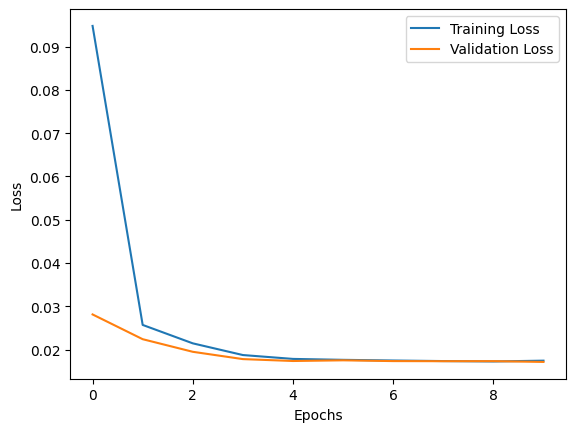

In [113]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [114]:
train_pred = model.predict(x_train)

train_error = np.mean(np.square(x_train - train_pred), axis=(1, 2))

threshold = np.mean(train_error) + 3 * np.std(train_error)

print("Threshold:", threshold)

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Threshold: 0.024040049709494103


In [115]:
test_pred = model.predict(x_test)

test_error = np.mean(np.square(x_test - test_pred), axis=(1, 2))

y_pred = (test_error > threshold).astype(int)

print("Detected Anomalies:", np.sum(y_pred))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Detected Anomalies: 28


In [116]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Confusion Matrix:
[[484   0]
 [484  28]]

Classification Report:
              precision    recall  f1-score   support

           0       0.50      1.00      0.67       484
           1       1.00      0.05      0.10       512

    accuracy                           0.51       996
   macro avg       0.75      0.53      0.39       996
weighted avg       0.76      0.51      0.38       996

